In [15]:
import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
from shapely import wkt
import altair as alt
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import shutil
import subprocess
import os
import folium
import folium.plugins
import datetime
alt.data_transformers.disable_max_rows()
import warnings
warnings.filterwarnings("ignore")



os.environ["JAVA_HOME"] = subprocess.run(
    ["/usr/libexec/java_home", "-v", "21"],
    capture_output=True, text=True, check=True
).stdout.strip()


from r5py.util.config import Config
import r5py

Number of intersections:  166955
Number of road segments: 507668


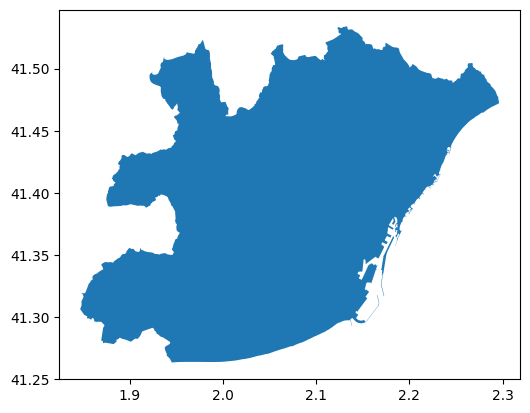

In [16]:
# Importing osmnx

# Define the polygon for the 1st district of Budapest
admin_district = ox.geocode_to_gdf('Àrea Metropolitana de Barcelona, Spain')
admin_district.plot()
admin_poly = admin_district.geometry.values[0]

# Load the graph from OSMnx
G = ox.graph_from_polygon(admin_poly, network_type='walk')

print('Number of intersections: ', G.number_of_nodes())
print('Number of road segments:',  G.number_of_edges())

In [18]:
neigh = pd.read_csv("Data/Neigh/neigh.csv")

neigh["geometry"] = neigh["geom"].apply(wkt.loads)

neigh = gpd.GeoDataFrame(
    neigh,
    geometry="geometry",
    crs="EPSG:4326"
)
neigh = neigh[["name", "geometry"]]
neigh["geometry"] = neigh.buffer(0)


neigh_layer = alt.Chart(neigh).mark_geoshape(
    stroke="black",
    fill="lightblue"
).properties(
    width=600,
    height=600
    
).encode(tooltip=['name'])

In [23]:
bus_sol = pd.read_csv('Nodes/N-Bus-Sol.csv')
bus = pd.read_csv('Nodes/N-Bus.csv')
fgc_sol = pd.read_csv('Nodes/N-FGC-Sol.csv')
fgc = pd.read_csv('Nodes/N-FGC.csv')
metro_sol = pd.read_csv('Nodes/N-Metro-Sol.csv')
metro = pd.read_csv('Nodes/N-Metro.csv')
tram_sol = pd.read_csv('Nodes/N-Tram-Sol.csv')
tram = pd.read_csv('Nodes/N-Tram.csv')

all_stops = pd.concat([bus_sol, bus, fgc_sol, fgc, metro_sol, metro, tram_sol, tram], ignore_index=True)
all_stops['geometry']= all_stops['geometry'].apply(wkt.loads)
all_stops = gpd.GeoDataFrame(all_stops, geometry='geometry', crs="EPSG:4326")
bus

,id,stop_id,name,linia,stop_type,geometry
0,B-59-2,2,Av Icària - Àlaba,59,Bus,POINT (2.198984998801282 41.393104003754864)
1,B-H16-2,2,Av Icària - Àlaba,H16,Bus,POINT (2.198984998801282 41.393104003754864)
2,B-V27-2,2,Av Icària - Àlaba,V27,Bus,POINT (2.198984998801282 41.393104003754864)
3,B-63-3,3,València - Muntaner,63,Bus,POINT (2.1578909990979396 41.388546000808674)
4,B-H10-3,3,València - Muntaner,H10,Bus,POINT (2.1578909990979396 41.388546000808674)
...,...,...,...,...,...,...
5669,B-87-112571,112571,Madrazo - Lincoln,87,Bus,POINT (2.149142146085151 41.40041980069335)
5670,B-B20-112593,112593,Font de l'Alzina,B20,Bus,POINT (2.198081890109135 41.45849127000909)
5671,B-M27-112593,112593,Font de l'Alzina,M27,Bus,POINT (2.198081890109135 41.45849127000909)
5672,B-87-112642,112642,"Gran de Gràcia, 160",87,Bus,POINT (2.152936029016472 41.402169559453306)


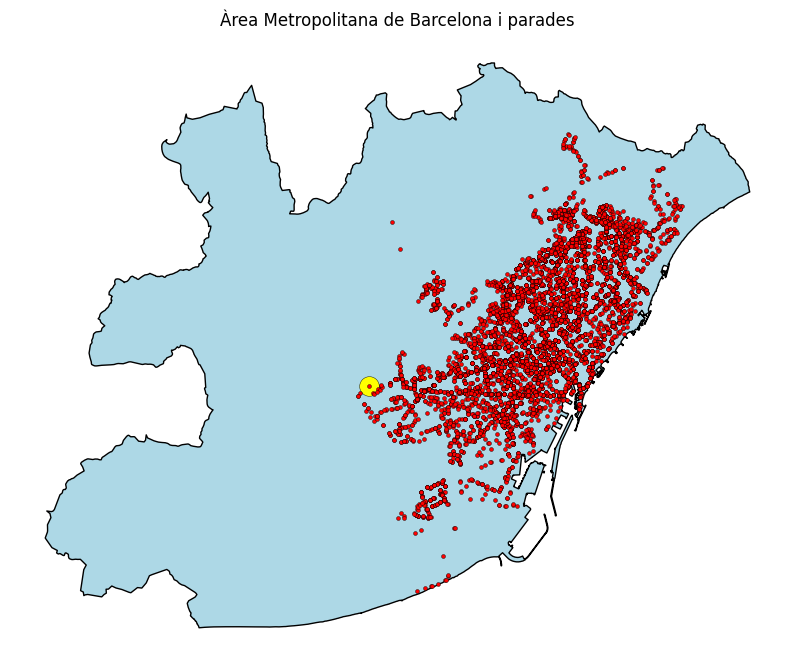

In [26]:
fig, ax = plt.subplots(figsize=(10, 10))

admin_district.plot(
    ax=ax,
    color="lightblue",
    edgecolor="black",
    linewidth=1
)

all_stops[all_stops['stop_id'] == 'CCML'].plot(
    ax=ax,
    color="yellow",
    markersize=200,
    edgecolor="black",
    linewidth=0.3
)

all_stops.plot(
    ax=ax,
    color="red",
    markersize=8,
    edgecolor="black",
    linewidth=0.3
)

ax.set_title("Àrea Metropolitana de Barcelona i parades")
ax.axis("off")
plt.show()

In [27]:
walking_speed = 1.39

for u, v, data in G.edges(data=True):
    data["travel_time"] = data["length"] / walking_speed


isochrone_time = 5
isochrone_polys = []

process = 1
for stop_type in all_stops['stop_type'].unique():
    stops_for_type = all_stops[all_stops['stop_type'] == stop_type]
    for stop in stops_for_type['stop_id'].unique():
        print(f"Processing stop {stop} ({process}/{len(all_stops['stop_id'].unique())})")

        process += 1
        p = stops_for_type[stops_for_type['stop_id'] == stop].iloc[0]
        center_node = ox.distance.nearest_nodes(G, X=p['geometry'].x, Y=p["geometry"].y)

        subgraph = nx.ego_graph(
                G,
                center_node,
                radius= isochrone_time * 60,
                distance="travel_time"
            )

        node_points = [
            Point((data["x"], data["y"]))
            for node, data in subgraph.nodes(data=True)
        ]

        center_point = Point(G.nodes[center_node]["x"], G.nodes[center_node]["y"])

        polygon = gpd.GeoSeries(node_points).union_all().convex_hull
        isochrone_polys.append(
                gpd.GeoDataFrame(
                    {"stop_id": [p["stop_id"]], 'stop_type': [p["stop_type"]], "geometry": [polygon]},
                    crs="EPSG:4326"
                )
            )

isochrone_polys = gpd.GeoDataFrame(pd.concat(isochrone_polys, ignore_index=True), crs="EPSG:4326")

Processing stop 2 (1/3266)
Processing stop 3 (2/3266)
Processing stop 7 (3/3266)
Processing stop 8 (4/3266)
Processing stop 13 (5/3266)
Processing stop 20 (6/3266)
Processing stop 21 (7/3266)
Processing stop 22 (8/3266)
Processing stop 24 (9/3266)
Processing stop 25 (10/3266)
Processing stop 32 (11/3266)
Processing stop 34 (12/3266)
Processing stop 38 (13/3266)
Processing stop 39 (14/3266)
Processing stop 41 (15/3266)
Processing stop 42 (16/3266)
Processing stop 43 (17/3266)
Processing stop 44 (18/3266)
Processing stop 48 (19/3266)
Processing stop 51 (20/3266)
Processing stop 55 (21/3266)
Processing stop 58 (22/3266)
Processing stop 60 (23/3266)
Processing stop 63 (24/3266)
Processing stop 65 (25/3266)
Processing stop 69 (26/3266)
Processing stop 82 (27/3266)
Processing stop 94 (28/3266)
Processing stop 95 (29/3266)
Processing stop 98 (30/3266)
Processing stop 103 (31/3266)
Processing stop 105 (32/3266)
Processing stop 106 (33/3266)
Processing stop 108 (34/3266)
Processing stop 109 (35

In [28]:
isocores_df_all = all_stops[all_stops['stop_id'].isin(isochrone_polys['stop_id'].unique())].merge(isochrone_polys, on=['stop_id','stop_type'], how='left')
isocores_df_all.drop(columns=['geometry_x'], inplace=True)
isocores_df_all.rename(columns={'geometry_y': 'geometry'}, inplace=True)
isocores_df_all.set_geometry('geometry', inplace=True)
isocores_df_all

,id,stop_id,name,linia,stop_type,geometry
0,SB-2,2,Av Icària - Àlaba,IU Stop,Bus,"POLYGON ((2.19864 41.39029, 2.19655 41.39061, ..."
1,SB-3,3,València - Muntaner,IU Stop,Bus,"POLYGON ((2.15827 41.38549, 2.15633 41.38565, ..."
2,SB-7,7,Pl Universitat,IU Stop,Bus,"POLYGON ((2.1637 41.3824, 2.15976 41.38319, 2...."
3,SB-8,8,Pl de Carles Buïgas,IU Stop,Bus,"POLYGON ((2.15159 41.36902, 2.14665 41.36923, ..."
4,SB-13,13,Sas - Claramunt,IU Stop,Bus,"POLYGON ((2.20584 41.4342, 2.20432 41.43434, 2..."
...,...,...,...,...,...,...
6765,T-T5-STJB,STJB,Sant Joan Baptista,T5,Tram,"POLYGON ((2.22446 41.42451, 2.22411 41.42458, ..."
6766,T-T5-NKNS,NKNS,Encants de Sant Adrià,T5,Tram,"POLYGON ((2.21987 41.42728, 2.21921 41.42804, ..."
6767,T-T5-STRC,STRC,Sant Roc,T5,Tram,"POLYGON ((2.22644 41.43243, 2.22467 41.43269, ..."
6768,T-T5-GORG,GORG,Gorg,T5,Tram,"POLYGON ((2.23004 41.43745, 2.22926 41.43984, ..."


In [29]:
test = all_stops.copy()
isocores_df_all_merge = isocores_df_all.copy()
test.to_crs('EPSG:25831', inplace=True)
isocores_df_all_merge.to_crs('EPSG:25831', inplace=True)
test.rename(columns={'id': 'destination_id','stop_id':'destination_stop_id','name':'destination_stop_name','linia':'destination_linia','stop_type':'destination_stop_type'}, inplace=True)
isocores_df_all_merge.rename(columns={'id': 'origin_id','stop_id':'origin_stop_id','name':'origin_stop_name','linia':'origin_linia','stop_type':'origin_stop_type'}, inplace=True)
close_stops = gpd.sjoin(test[test['destination_id'].isin(isocores_df_all_merge['origin_id'])], isocores_df_all_merge, how='inner', predicate='within')
close_stops = close_stops[close_stops['origin_id'] != close_stops['destination_id']]
close_stops = close_stops[~close_stops['destination_id'].str.startswith('S')]
close_stops = close_stops[['origin_id', 'origin_stop_id', 'origin_stop_type', 'origin_stop_name', 'origin_linia', 'destination_id', 'destination_stop_id', 'destination_stop_type', 'destination_stop_name', 'destination_linia']]
close_stops['tram'] = close_stops['origin_stop_name'] + ' - ' + close_stops['destination_stop_name']
close_stops['mode'] = close_stops['origin_stop_type'] + ' - ' + close_stops['destination_stop_type']
close_stops['lines'] = close_stops['origin_linia'] + ' - ' + close_stops['destination_linia']
close_stops.drop(columns=['origin_stop_name', 'destination_stop_name','origin_linia','destination_linia'], inplace=True)
close_stops

,origin_id,origin_stop_id,origin_stop_type,destination_id,destination_stop_id,destination_stop_type,tram,mode,lines
739,SB-2,2,Bus,B-59-2,2,Bus,Av Icària - Àlaba - Av Icària - Àlaba,Bus - Bus,IU Stop - 59
739,SB-34,34,Bus,B-59-2,2,Bus,Av Icària - Av Bogatell - Av Icària - Àlaba,Bus - Bus,IU Stop - 59
739,SB-342,342,Bus,B-59-2,2,Bus,Cementiri de l'Est - Av Icària - Àlaba,Bus - Bus,IU Stop - 59
739,SB-698,698,Bus,B-59-2,2,Bus,Av Icària - Joan Miró - Av Icària - Àlaba,Bus - Bus,IU Stop - 59
739,B-H16-2,2,Bus,B-59-2,2,Bus,Av Icària - Àlaba - Av Icària - Àlaba,Bus - Bus,H16 - 59
...,...,...,...,...,...,...,...,...,...
6769,B-V33-3596,3596,Bus,T-T6-MINA,MINA,Tram,La Mina - Ponent - La Mina,Bus - Tram,V33 - T6
6769,B-B23-105999,105999,Bus,T-T6-MINA,MINA,Tram,Rambla de la Mina - La Mina,Bus - Tram,B23 - T6
6769,B-B23-106000,106000,Bus,T-T6-MINA,MINA,Tram,CAP La Mina - La Mina,Bus - Tram,B23 - T6
6769,T-T5-PARC,PARC,Tram,T-T6-MINA,MINA,Tram,Parc del Besòs - La Mina,Tram - Tram,T5 - T6


In [30]:
same_stops = close_stops[
    (close_stops['origin_stop_id'] == close_stops['destination_stop_id']) & (close_stops['origin_stop_type'] == close_stops['destination_stop_type'])
].copy()
same_stops = same_stops.drop(columns=['origin_stop_id', 'destination_stop_id'])

conditions = [
    same_stops['origin_id'].str.startswith('S', na=False) & same_stops['destination_id'].str.startswith(('M', 'F'), na=False),
    same_stops['origin_id'].str.startswith('S', na=False) & same_stops['destination_id'].str.startswith('B', na=False),
    same_stops['origin_id'].str.startswith('S', na=False) & same_stops['destination_id'].str.startswith('T', na=False),
    same_stops['origin_id'].str.startswith('B', na=False) & same_stops['destination_id'].str.startswith('B', na=False),
    same_stops['origin_id'].str.startswith(('M', 'F'), na=False) & same_stops['destination_id'].str.startswith(('M', 'F'), na=False),
    same_stops['origin_id'].str.startswith('T', na=False) & same_stops['destination_id'].str.startswith('T', na=False),

]
choices = [3, 1, 2, 1, 2, 1]
same_stops['type'] = 'Exchange - Self'
same_stops['time'] = np.select(conditions, choices, default=0)
# same_stops['time'] = pd.to_timedelta(
#     np.select(conditions, choices, default=0),
#     unit='m'
# )

# same_stops['time'] = same_stops['time'].apply(
#     lambda x: f"{int(x.total_seconds() // 60):02d}:{int(x.total_seconds() % 60):02d}"
# )
same_stops['geometry'] = same_stops.apply(lambda row: all_stops.loc[all_stops['id'] == row['origin_id'], 'geometry'].values[0], axis=1)
same_stops.drop(columns=['origin_stop_type', 'destination_stop_type'], inplace=True)
same_stops


,origin_id,destination_id,tram,mode,lines,type,time,geometry
739,SB-2,B-59-2,Av Icària - Àlaba - Av Icària - Àlaba,Bus - Bus,IU Stop - 59,Exchange - Self,1,POINT (2.198984998801282 41.393104003754864)
739,B-H16-2,B-59-2,Av Icària - Àlaba - Av Icària - Àlaba,Bus - Bus,H16 - 59,Exchange - Self,1,POINT (2.198984998801282 41.393104003754864)
739,B-V27-2,B-59-2,Av Icària - Àlaba - Av Icària - Àlaba,Bus - Bus,V27 - 59,Exchange - Self,1,POINT (2.198984998801282 41.393104003754864)
740,SB-2,B-H16-2,Av Icària - Àlaba - Av Icària - Àlaba,Bus - Bus,IU Stop - H16,Exchange - Self,1,POINT (2.198984998801282 41.393104003754864)
740,B-59-2,B-H16-2,Av Icària - Àlaba - Av Icària - Àlaba,Bus - Bus,59 - H16,Exchange - Self,1,POINT (2.198984998801282 41.393104003754864)
...,...,...,...,...,...,...,...,...
6760,T-T6-ALFS,T-T5-ALFS,Alfons el Magnànim - Alfons el Magnànim,Tram - Tram,T6 - T5,Exchange - Self,1,POINT (2.213568925857544 41.41719055175781)
6761,ST-ALFS,T-T6-ALFS,Alfons el Magnànim - Alfons el Magnànim,Tram - Tram,IU Stop - T6,Exchange - Self,2,POINT (2.213568925857544 41.41719055175781)
6761,T-T5-ALFS,T-T6-ALFS,Alfons el Magnànim - Alfons el Magnànim,Tram - Tram,T5 - T6,Exchange - Self,1,POINT (2.213568925857544 41.41719055175781)
6762,T-T6-PARC,T-T5-PARC,Parc del Besòs - Parc del Besòs,Tram - Tram,T6 - T5,Exchange - Self,1,POINT (2.217633008956909 41.419429779052734)


In [92]:
# cache_dir = Config().CACHE_DIR
# for f in cache_dir.glob("*.mapdb*"):
#     f.unlink()

In [31]:
transport_network = r5py.TransportNetwork(
    "Data/Neigh/cataluna-260811.osm.pbf",
    elevation_model =["Data/Neigh/elevacions-terreny-lidar-Catalunya-2m-2008-2011tif1786456535055.tif"]
    )

In [32]:
itineraries = pd.DataFrame()
process = 0
failed_iteraries = []
different_stops = close_stops[
    (close_stops['origin_stop_id'] != close_stops['destination_stop_id'])
]


for stop_type in different_stops['origin_stop_type'].unique():
    stops_for_type = different_stops[different_stops['origin_stop_type'] == stop_type]
    for stop in stops_for_type['origin_stop_id'].unique():
        process += 1
        print(f"Processing {process}/{stops_for_type['origin_stop_id'].nunique()}")
        stops = stops_for_type[stops_for_type['origin_stop_id'] == stop]
        stops.drop_duplicates(subset=['origin_stop_id', 'destination_stop_id'], inplace=True)

        for _, row in stops.iterrows():
            origin_id = row['origin_stop_id']
            destination_id = row['destination_stop_id']
            # if origin_id  != 1323:
            #     continue
            # if destination_id != 2:
            #     continue

            # if process != 2374:
            #     continue
            print
            origins = all_stops[(all_stops['stop_id'] == origin_id) & (all_stops['stop_type'] == stop_type)].copy()
            origins.drop_duplicates(subset=['stop_id'], inplace=True)
            destinations = all_stops[all_stops['stop_id'] == destination_id].copy()
            destinations.drop_duplicates(subset=['stop_id'], inplace=True)
            origins.rename(columns={'origin_id': 'id'}, inplace=True)
            destinations.rename(columns={'destination_id': 'id'}, inplace=True)
            origins = gpd.GeoDataFrame(origins, geometry='geometry', crs="EPSG:4326")
            destinations = gpd.GeoDataFrame(destinations, geometry='geometry', crs="EPSG:4326")
            detailed_itineraries = r5py.DetailedItineraries(
                transport_network,
                origins=origins,
                destinations=destinations,
                transport_modes=[r5py.TransportMode.WALK],
                snap_to_network=True,
                speed_walking = 5,
                departure=datetime.datetime(2026, 5, 13, 9, 30),

            )

            if len(detailed_itineraries) == 0:
                failed_iteraries.append((origin_id, destination_id))
                continue
            exchange_time = detailed_itineraries['travel_time'].sum()
            itineraries_row = pd.DataFrame({
                'origin_stop_id': [origin_id],
                'destination_stop_id': [destination_id],
                'origin_type': [stop_type],
                'destination_type': [row['destination_stop_type']],
                'time': [exchange_time],
                'geometry': [detailed_itineraries['geometry'].iloc[0]],
            })

            itineraries_row = gpd.GeoDataFrame(itineraries_row, geometry='geometry', crs="EPSG:4326")
            itineraries = pd.concat([itineraries, itineraries_row], ignore_index=True)


itineraries["time"] = itineraries["time"].apply(
    lambda x: x.total_seconds() / 60
)


Processing 1/3111
Processing 2/3111
Processing 3/3111
Processing 4/3111
Processing 5/3111
Processing 6/3111
Processing 7/3111
Processing 8/3111
Processing 9/3111
Processing 10/3111
Processing 11/3111
Processing 12/3111
Processing 13/3111
Processing 14/3111
Processing 15/3111
Processing 16/3111
Processing 17/3111
Processing 18/3111
Processing 19/3111
Processing 20/3111
Processing 21/3111
Processing 22/3111
Processing 23/3111
Processing 24/3111
Processing 25/3111
Processing 26/3111
Processing 27/3111
Processing 28/3111
Processing 29/3111
Processing 30/3111
Processing 31/3111
Processing 32/3111
Processing 33/3111
Processing 34/3111
Processing 35/3111
Processing 36/3111
Processing 37/3111
Processing 38/3111
Processing 39/3111
Processing 40/3111
Processing 41/3111
Processing 42/3111
Processing 43/3111
Processing 44/3111
Processing 45/3111
Processing 46/3111
Processing 47/3111
Processing 48/3111
Processing 49/3111
Processing 50/3111
Processing 51/3111
Processing 52/3111
Processing 53/3111
Pr

In [33]:
different_stops_final = different_stops.merge(itineraries, 
                                              left_on=['origin_stop_id', 'origin_stop_type', 'destination_stop_id', 'destination_stop_type'], 
                                              right_on=['origin_stop_id', 'origin_type', 'destination_stop_id', 'destination_type'], 
                                              how='left')
different_stops_final.drop(columns=['origin_stop_id', 'destination_stop_id','destination_stop_type','origin_stop_type','origin_type','destination_type'], inplace=True)
different_stops_final.insert(5, 'type', 'Exchange')
different_stops_final = different_stops_final[different_stops_final['geometry'].notnull()]
different_stops_final
origin_is_iu = different_stops_final['origin_id'].str.startswith('S', na=False)
different_stops_final.loc[origin_is_iu, 'mode'] = (
    'IU + ' + different_stops_final.loc[origin_is_iu, 'mode']
)
different_stops_final['time'] =np.where(
    different_stops_final['mode'].str.startswith(('Metro', 'FGC')) | different_stops_final['mode'].str.endswith(('Metro', 'FGC')),
    different_stops_final['time'] + 2,
    different_stops_final['time']
)
different_stops_final


,origin_id,destination_id,tram,mode,lines,type,time,geometry
0,SB-34,B-59-2,Av Icària - Av Bogatell - Av Icària - Àlaba,IU + Bus - Bus,IU Stop - 59,Exchange,0.816667,"LINESTRING (2.19972 41.39341, 2.1997 41.39339,..."
1,SB-342,B-59-2,Cementiri de l'Est - Av Icària - Àlaba,IU + Bus - Bus,IU Stop - 59,Exchange,5.000000,"LINESTRING (2.20291 41.3947, 2.20226 41.39416,..."
2,SB-698,B-59-2,Av Icària - Joan Miró - Av Icària - Àlaba,IU + Bus - Bus,IU Stop - 59,Exchange,4.833333,"LINESTRING (2.19587 41.39, 2.19608 41.3902, 2...."
3,B-H16-34,B-59-2,Av Icària - Av Bogatell - Av Icària - Àlaba,Bus - Bus,H16 - 59,Exchange,0.816667,"LINESTRING (2.19972 41.39341, 2.1997 41.39339,..."
4,B-V27-34,B-59-2,Av Icària - Av Bogatell - Av Icària - Àlaba,Bus - Bus,V27 - 59,Exchange,0.816667,"LINESTRING (2.19972 41.39341, 2.1997 41.39339,..."
...,...,...,...,...,...,...,...,...
140317,B-V33-3596,T-T6-MINA,La Mina - Ponent - La Mina,Bus - Tram,V33 - T6,Exchange,4.566667,"LINESTRING (2.21728 41.41881, 2.2174 41.41866,..."
140318,B-B23-105999,T-T6-MINA,Rambla de la Mina - La Mina,Bus - Tram,B23 - T6,Exchange,1.800000,"LINESTRING (2.22243 41.41822, 2.22234 41.41811..."
140319,B-B23-106000,T-T6-MINA,CAP La Mina - La Mina,Bus - Tram,B23 - T6,Exchange,4.166667,"LINESTRING (2.22018 41.41563, 2.22041 41.41589..."
140320,T-T5-PARC,T-T6-MINA,Parc del Besòs - La Mina,Tram - Tram,T5 - T6,Exchange,4.850000,"LINESTRING (2.21713 41.41916, 2.21717 41.41919..."


In [34]:
all_exchanges = pd.concat([same_stops, different_stops_final], ignore_index=True)
all_exchanges.rename(columns={'origin_id': 'origen', 'destination_id': 'dest','exchange_time':'time'}, inplace=True)
#all_exchanges = gpd.GeoDataFrame(all_exchanges, geometry='geometry', crs="EPSG:4326")
all_exchanges = all_exchanges[all_exchanges['time'] <= 5]
all_exchanges.insert(7, 'directed', True)

In [35]:
all_exchanges.to_csv('Edges/Exchanges.csv', index=False)

In [ ]:
# Frame 1: polygons only
isochrone_chart = alt.Chart(isocores_df_all[isocores_df_all['stop_id'].isin([2575])]).mark_geoshape(
    stroke='black',
    strokeWidth=1
).encode(tooltip=['id'])

points = alt.Chart(all_stops[all_stops['stop_id'].isin([2575,84])]).mark_geoshape(
    fill='red',
    stroke='black',
    strokeWidth=1,
    size=0
).encode(
    tooltip=['name']
)

itineraries_chart = alt.Chart(all_exchanges[all_exchanges['origen'].isin(['B-B80-2575']) & (all_exchanges['dest'].isin(['B-B18-84']))]).mark_geoshape(
    filled = False,
    stroke='black',
    strokeWidth=1,
    size=0
)


(
isochrone_chart + points + itineraries_chart  ).properties(
    width=900,
    height=900
)

In [ ]:
# Frame 1: polygons only
polys_df = isocores_df_all[['id', 'geometry']].copy()
polys_df = gpd.GeoDataFrame(polys_df, geometry='geometry', crs="EPSG:4326")


not_self_exchanges = all_exchanges[all_exchanges['type'] == 'Exchange'].copy()
#not_self_exchanges = not_self_exchanges[not_self_exchanges['mode'] == 'Bus - Tram']
origens = not_self_exchanges['origen'].unique().tolist()
destinations = not_self_exchanges['dest'].unique().tolist()
stops =  origens + destinations

isochrone_chart = alt.Chart(polys_df[polys_df['id'].isin(origens)]).mark_geoshape(
    stroke='black',
    strokeWidth=1
).encode(tooltip=['id'])

points = alt.Chart(all_stops[all_stops['id'].isin(stops)]).mark_geoshape(
    fill='red',
    stroke='black',
    strokeWidth=1,
    size=0
).encode(
    tooltip=['name']
)

itineraries_chart = alt.Chart(not_self_exchanges).mark_geoshape(
    filled = False,
    stroke='black',
    strokeWidth=1,
    size=0
)


(
neigh_layer + isochrone_chart).properties(
    width=900,
    height=900
)

In [ ]:



# ---------------------------------------------------------
# Load neighbourhoods
# ---------------------------------------------------------

neigh = pd.read_csv("Data/Neigh/neigh.csv")

neigh["geometry"] = neigh["geom"].apply(wkt.loads)

neigh = gpd.GeoDataFrame(
    neigh,
    geometry="geometry",
    crs="EPSG:4326"
)

neigh = neigh[["name", "geometry"]]

neigh["geometry"] = neigh.geometry.buffer(0)


# ---------------------------------------------------------
# Prepare itinerary data
# ---------------------------------------------------------

itineraries["mode"] = itineraries["transport_mode"].astype(str)

itineraries["travel time (min)"] = itineraries["travel_time"].apply(
    lambda t: round(t.total_seconds() / 60.0, 2)
)

itineraries["trip"] = itineraries.apply(
    lambda row: f"{row['from_id']} → {row['to_id']}",
    axis=1
)


# ---------------------------------------------------------
# Create map
# ---------------------------------------------------------



detailed_routes_map = (
    itineraries[
        [
            "geometry",
            "distance",
            "mode",
            "travel time (min)",
            "from_id",
            "to_id",
            "trip",
            "option",
            "segment",
        ]
    ]
    .explore(
        tooltip=[
            "trip",
            "option",
            "segment",
            "mode",
            "travel time (min)",
            "distance",
        ],
        column="mode",
        tiles="CartoDB.Positron",
        style_kwds={
            "weight": 3,
            "opacity": 0.8,
        },
        highlight_kwds={
            "weight": 6,
            "opacity": 1,
        },
    )
)


isochrone_polys.explore(
    m=detailed_routes_map,
    tooltip=["stop_id"],
    style_kwds={
        "fillOpacity": 0.15,
        "weight": 1,
    },
)

# ---------------------------------------------------------
# Get stops involved in the itineraries
# ---------------------------------------------------------

stop_ids = pd.unique(
    pd.concat([
        itineraries["from_id"],
        itineraries["to_id"]
    ])
)

stops_map = all_stops[
    all_stops["id"].isin(stop_ids)
].copy()

stops_map = gpd.GeoDataFrame(
    stops_map,
    geometry="geometry",
    crs="EPSG:4326"
)


# ---------------------------------------------------------
# Assign neighbourhood to each stop
# ---------------------------------------------------------

# Project both layers for the spatial join
stops_projected = stops_map.to_crs("EPSG:25831")
neigh_projected = neigh.to_crs("EPSG:25831")

stops_map = gpd.sjoin(
    stops_projected,
    neigh_projected[["name", "geometry"]],
    how="left",
    predicate="within"
)

# Return to WGS84 for Folium
stops_map = stops_map.to_crs("EPSG:4326")


# ---------------------------------------------------------
# Add stop markers
# ---------------------------------------------------------

stops_map.apply(
    lambda row: folium.Marker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        tooltip=(
            f"Stop: {row['id']}<br>"
        ),
        icon=folium.plugins.BeautifyIcon(
            icon_shape="marker",
            number=str(row["id"]),
            border_color="#728224",
            text_color="#728224",
        ),
    ).add_to(detailed_routes_map),
    axis=1,
)


detailed_routes_map